# Regresión logística y regresión múltiple
Aplicación en seguros.

> **Nota:** dataset ficticio de 6 clientes de una aseguradora (solo 2 quedan en el conjunto de prueba), creado para practicar la técnica. Sirve para ilustrar el procedimiento, no para sacar conclusiones generalizables.

In [2]:
# Importar librerías necesarias
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    mean_squared_error, mean_absolute_error, r2_score
)


## 1. Simulación del Dataset

In [3]:
# Simulación de datos
data = {
    "Edad": [25, 40, 32, 50, 28, 45],
    "Ingresos": [30000, 55000, 42000, 60000, 37000, 52000],
    "Historial_Accidentes": [1, 0, 1, 0, 1, 0],
    "Monto_Reclamo": [5000, 0, 7500, 0, 6500, 0],
    "Reclamo": [1, 0, 1, 0, 1, 0]  # 1: Sí, 0: No
}

# Crear DataFrame
df = pd.DataFrame(data)

# Mostrar los primeros datos
df.head()


   Edad  Ingresos  Historial_Accidentes  Monto_Reclamo  Reclamo
0    25     30000                     1           5000        1
1    40     55000                     0              0        0
2    32     42000                     1           7500        1
3    50     60000                     0              0        0
4    28     37000                     1           6500        1

## 2. Preprocesamiento de Datos

In [4]:
# Variables predictoras y objetivo para Clasificación
X_class = df[["Edad", "Ingresos", "Historial_Accidentes"]]
y_class = df["Reclamo"]

# Variables predictoras y objetivo para Regresión
X_reg = df[["Edad", "Ingresos", "Historial_Accidentes"]]
y_reg = df["Monto_Reclamo"]

# División en entrenamiento y prueba
X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(
    X_class, y_class, test_size=0.2, random_state=42
)

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)


## 3. Modelo de Regresión Logística (Clasificación)


--- Regresión Logística: Predicción de Reclamos ---
Precisión: 1.00

Matriz de Confusión:
 [[1 0]
 [0 1]]

Reporte de Clasificación:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00         1
           1       1.00      1.00      1.00         1

    accuracy                           1.00         2
   macro avg       1.00      1.00      1.00         2
weighted avg       1.00      1.00      1.00         2



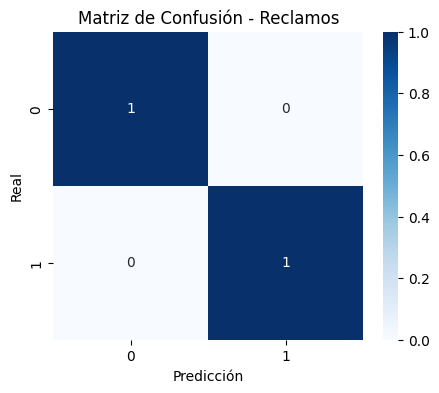

In [5]:
log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train_class, y_train_class)

# Predicción
y_pred_class = log_model.predict(X_test_class)

# Evaluación
print("\n--- Regresión Logística: Predicción de Reclamos ---")
print(f"Precisión: {accuracy_score(y_test_class, y_pred_class):.2f}")
print("\nMatriz de Confusión:\n", confusion_matrix(y_test_class, y_pred_class))
print("\nReporte de Clasificación:\n", classification_report(y_test_class, y_pred_class))

# Visualización de la Matriz de Confusión
plt.figure(figsize=(5,4))
sns.heatmap(confusion_matrix(y_test_class, y_pred_class), annot=True, cmap='Blues', fmt='d')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.title('Matriz de Confusión - Reclamos')
plt.show()


## 4. Modelo de Regresión Múltiple (Regresión)


--- Regresión Múltiple: Estimación del Monto del Reclamo ---
R²: -4.69
MSE: 35584183.67
MAE: 5464.29


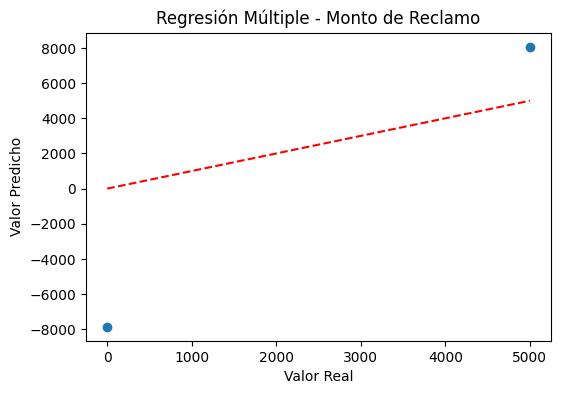

In [6]:
reg_model = LinearRegression()
reg_model.fit(X_train_reg, y_train_reg)

# Predicción
y_pred_reg = reg_model.predict(X_test_reg)

# Evaluación
print("\n--- Regresión Múltiple: Estimación del Monto del Reclamo ---")
print(f"R²: {r2_score(y_test_reg, y_pred_reg):.2f}")
print(f"MSE: {mean_squared_error(y_test_reg, y_pred_reg):.2f}")
print(f"MAE: {mean_absolute_error(y_test_reg, y_pred_reg):.2f}")

# Visualización de Resultados
plt.figure(figsize=(6,4))
plt.scatter(y_test_reg, y_pred_reg)
plt.plot([y_test_reg.min(), y_test_reg.max()], [y_test_reg.min(), y_test_reg.max()], 'r--')
plt.xlabel("Valor Real")
plt.ylabel("Valor Predicho")
plt.title("Regresión Múltiple - Monto de Reclamo")
plt.show()


## 5. Interacción con una IA (Sugerencia de Modelado)

Sugiero incluir variables adicionales como tipo de seguro, años con la compañía y lugar de residencia. Además, podrías probar algoritmos más robustos como Random Forest para clasificación y regresión.

## 6. Conclusiones

- La regresión logística clasifica bien los 2 casos de prueba, pero con solo 6 registros ese 100 % de precisión **no es evidencia de un buen modelo**: con tan pocos datos el resultado depende casi del azar.
- La regresión múltiple **no estima bien** el monto del reclamo: un R² negativo (−4,69) significa que predice peor que usar simplemente el promedio.
- La IA recomendó aumentar la cantidad de variables predictoras y utilizar modelos avanzados, lo cual es coherente con las estrategias aprendidas.
- Para mejorar: más registros, más variables y validación cruzada en lugar de una única partición.
